In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# =============================
# Step 1: Load Excel file
# =============================
file_path = "/mnt/f/Solar-Review-Ppaer/Monthwise-Data-Sheets/Data_clean/10-Minute-Average-Data/10-min-AVG-Data.xlsx"
df = pd.read_excel(file_path)

# =============================
# Step 2: Select relevant columns
# =============================
df = df[['DateTime', 'GHI']]
df['DateTime'] = pd.to_datetime(df['DateTime'])

# =============================
# Step 3: Remove zeros and NaN values from GHI
# =============================
df = df[df['GHI'].notna()]          # remove NaN values
df = df[df['GHI'] != 0]             # remove zeros

# (optional) Reset index after filtering
df = df.reset_index(drop=True)

df.isna().sum()

DateTime    0
GHI         0
dtype: int64

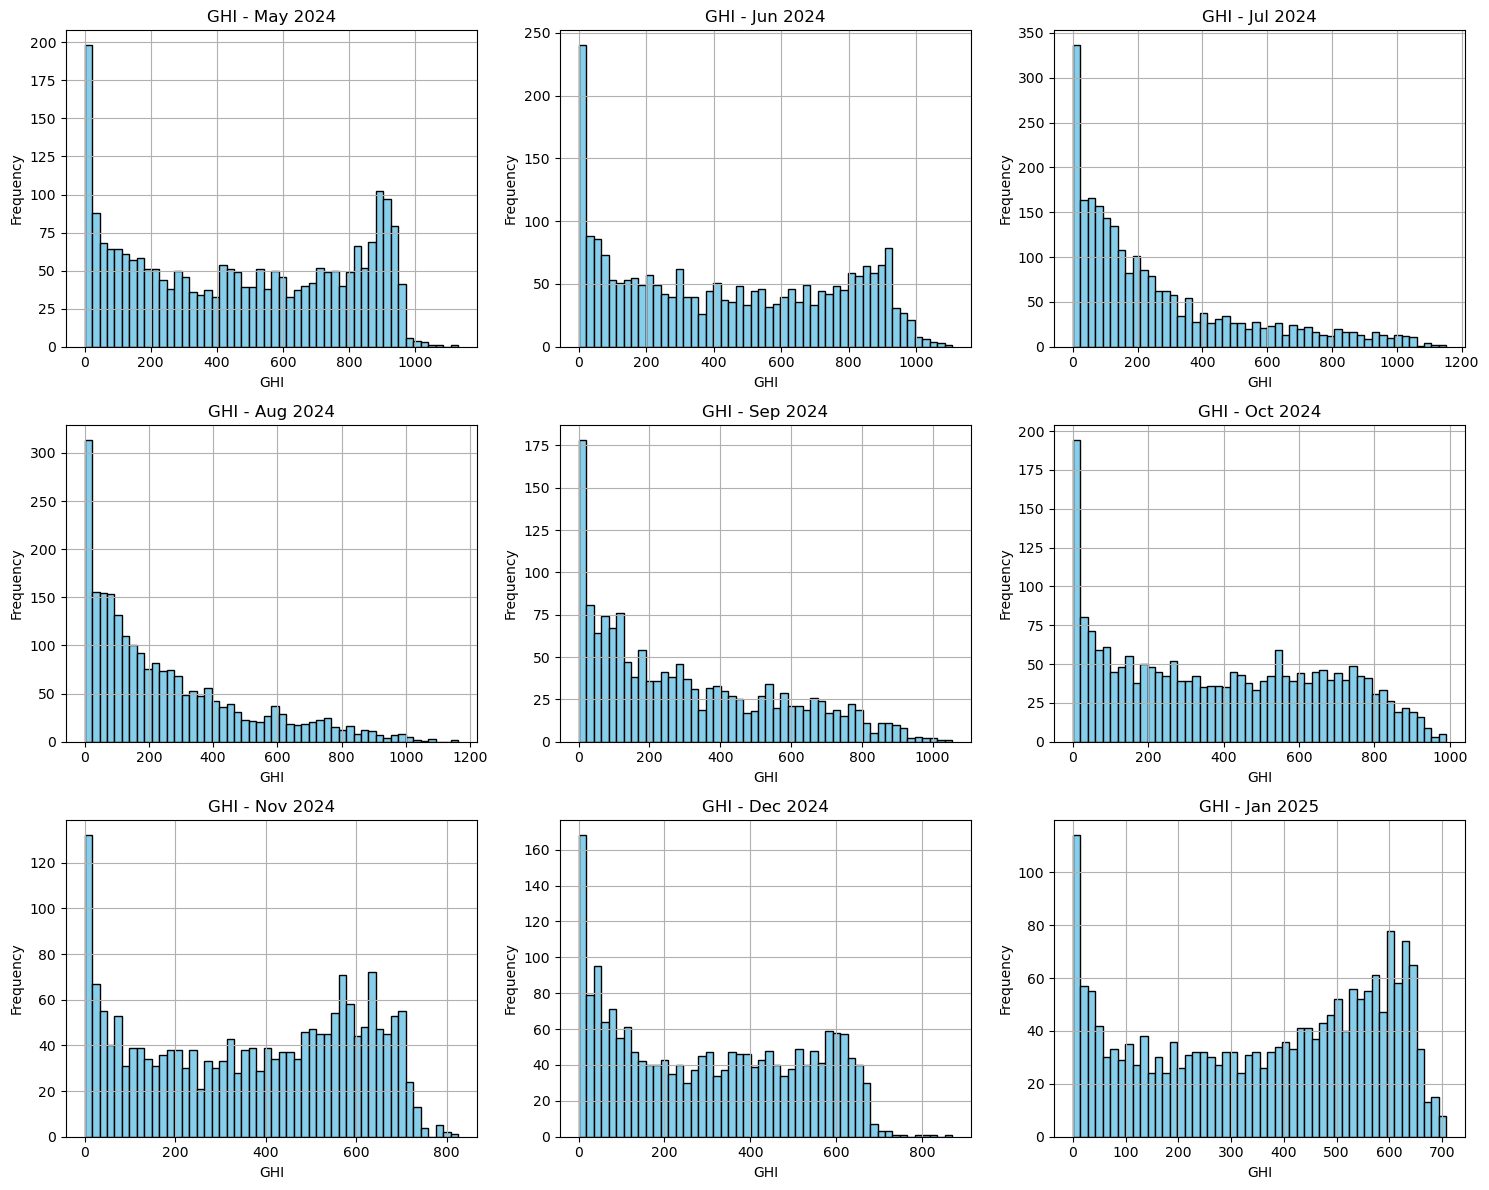

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# =============================
# Step 2: Ensure 'DateTime' column and filter 1-year data
# =============================
df['DateTime'] = pd.to_datetime(df['DateTime'])
mask = (df['DateTime'] >= '2024-04-01') & (df['DateTime'] < '2025-04-01')
df_year = df.loc[mask]

# =============================
# Step 3: Create month-wise histograms with 3x3 subplots
# =============================
months = pd.date_range('2024-04-05', '2025-03-31', freq='MS')

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, month_start in enumerate(months[:9]):  # only first 9 months per figure
    month_end = month_start + pd.offsets.MonthEnd(1)
    df_month = df_year[(df_year['DateTime'] >= month_start) & (df_year['DateTime'] <= month_end)]

    ax = axes[i]
    if df_month.empty:
        ax.axis('off')
        continue

    ax.hist(df_month['GHI'].dropna(), bins=50, color='skyblue', edgecolor='black')
    ax.set_title(f"GHI - {month_start.strftime('%b %Y')}")
    ax.set_xlabel("GHI")
    ax.set_ylabel("Frequency")
    ax.grid(True)

# Hide any unused subplots (in case fewer than 9)
for j in range(len(months), 9):
    axes[j].axis('off')

plt.tight_layout()
plt.show()
